# RQ2 Authorship Attribution

In [1]:
from pathlib import Path
import sys

root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(root))

from src.authorship_attribution import run_experiment

summary = run_experiment(
    input_path=root / 'data/processed/update2_features.pkl',
    results_dir=root / 'data/results/update2',
    figures_dir=root / 'figures/update2',
    bootstrap_samples=2000,
)
summary

{'feature_count': 23,
 'model': 'class-balanced RBF-SVM (C=1.0)',
 'training_stage': 'T0 only',
 'split_unit': 'group_id',
 'split_stratification': 'dataset',
 'random_state': 42,
 'test_size': 0.2,
 'train_groups': 2416,
 'test_groups': 604,
 'train_unique_t0_origins': 15469,
 'bootstrap_samples': 2000,
 'largest_drop_stage': 'T1',
 'largest_adjacent_macro_f1_drop': 0.13976293095432424,
 'undetectable_stage': None}

In [2]:
import pandas as pd

metrics = pd.read_csv(root / 'data/results/update2/rq2_authorship_metrics.csv')
metrics[[
    'stage', 'n', 'accuracy', 'balanced_accuracy',
    'precision_macro', 'recall_macro', 'f1_macro', 'recall_human'
]].round(3)

,stage,n,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,recall_human
0,T0,3873,0.774,0.800,0.678,0.800,0.693,0.838
1,T1,26598,0.624,0.669,0.589,0.669,0.553,0.735
2,T2,26598,0.613,0.646,0.577,0.646,0.539,0.693
3,T3,26598,0.614,0.631,0.569,0.631,0.535,0.655


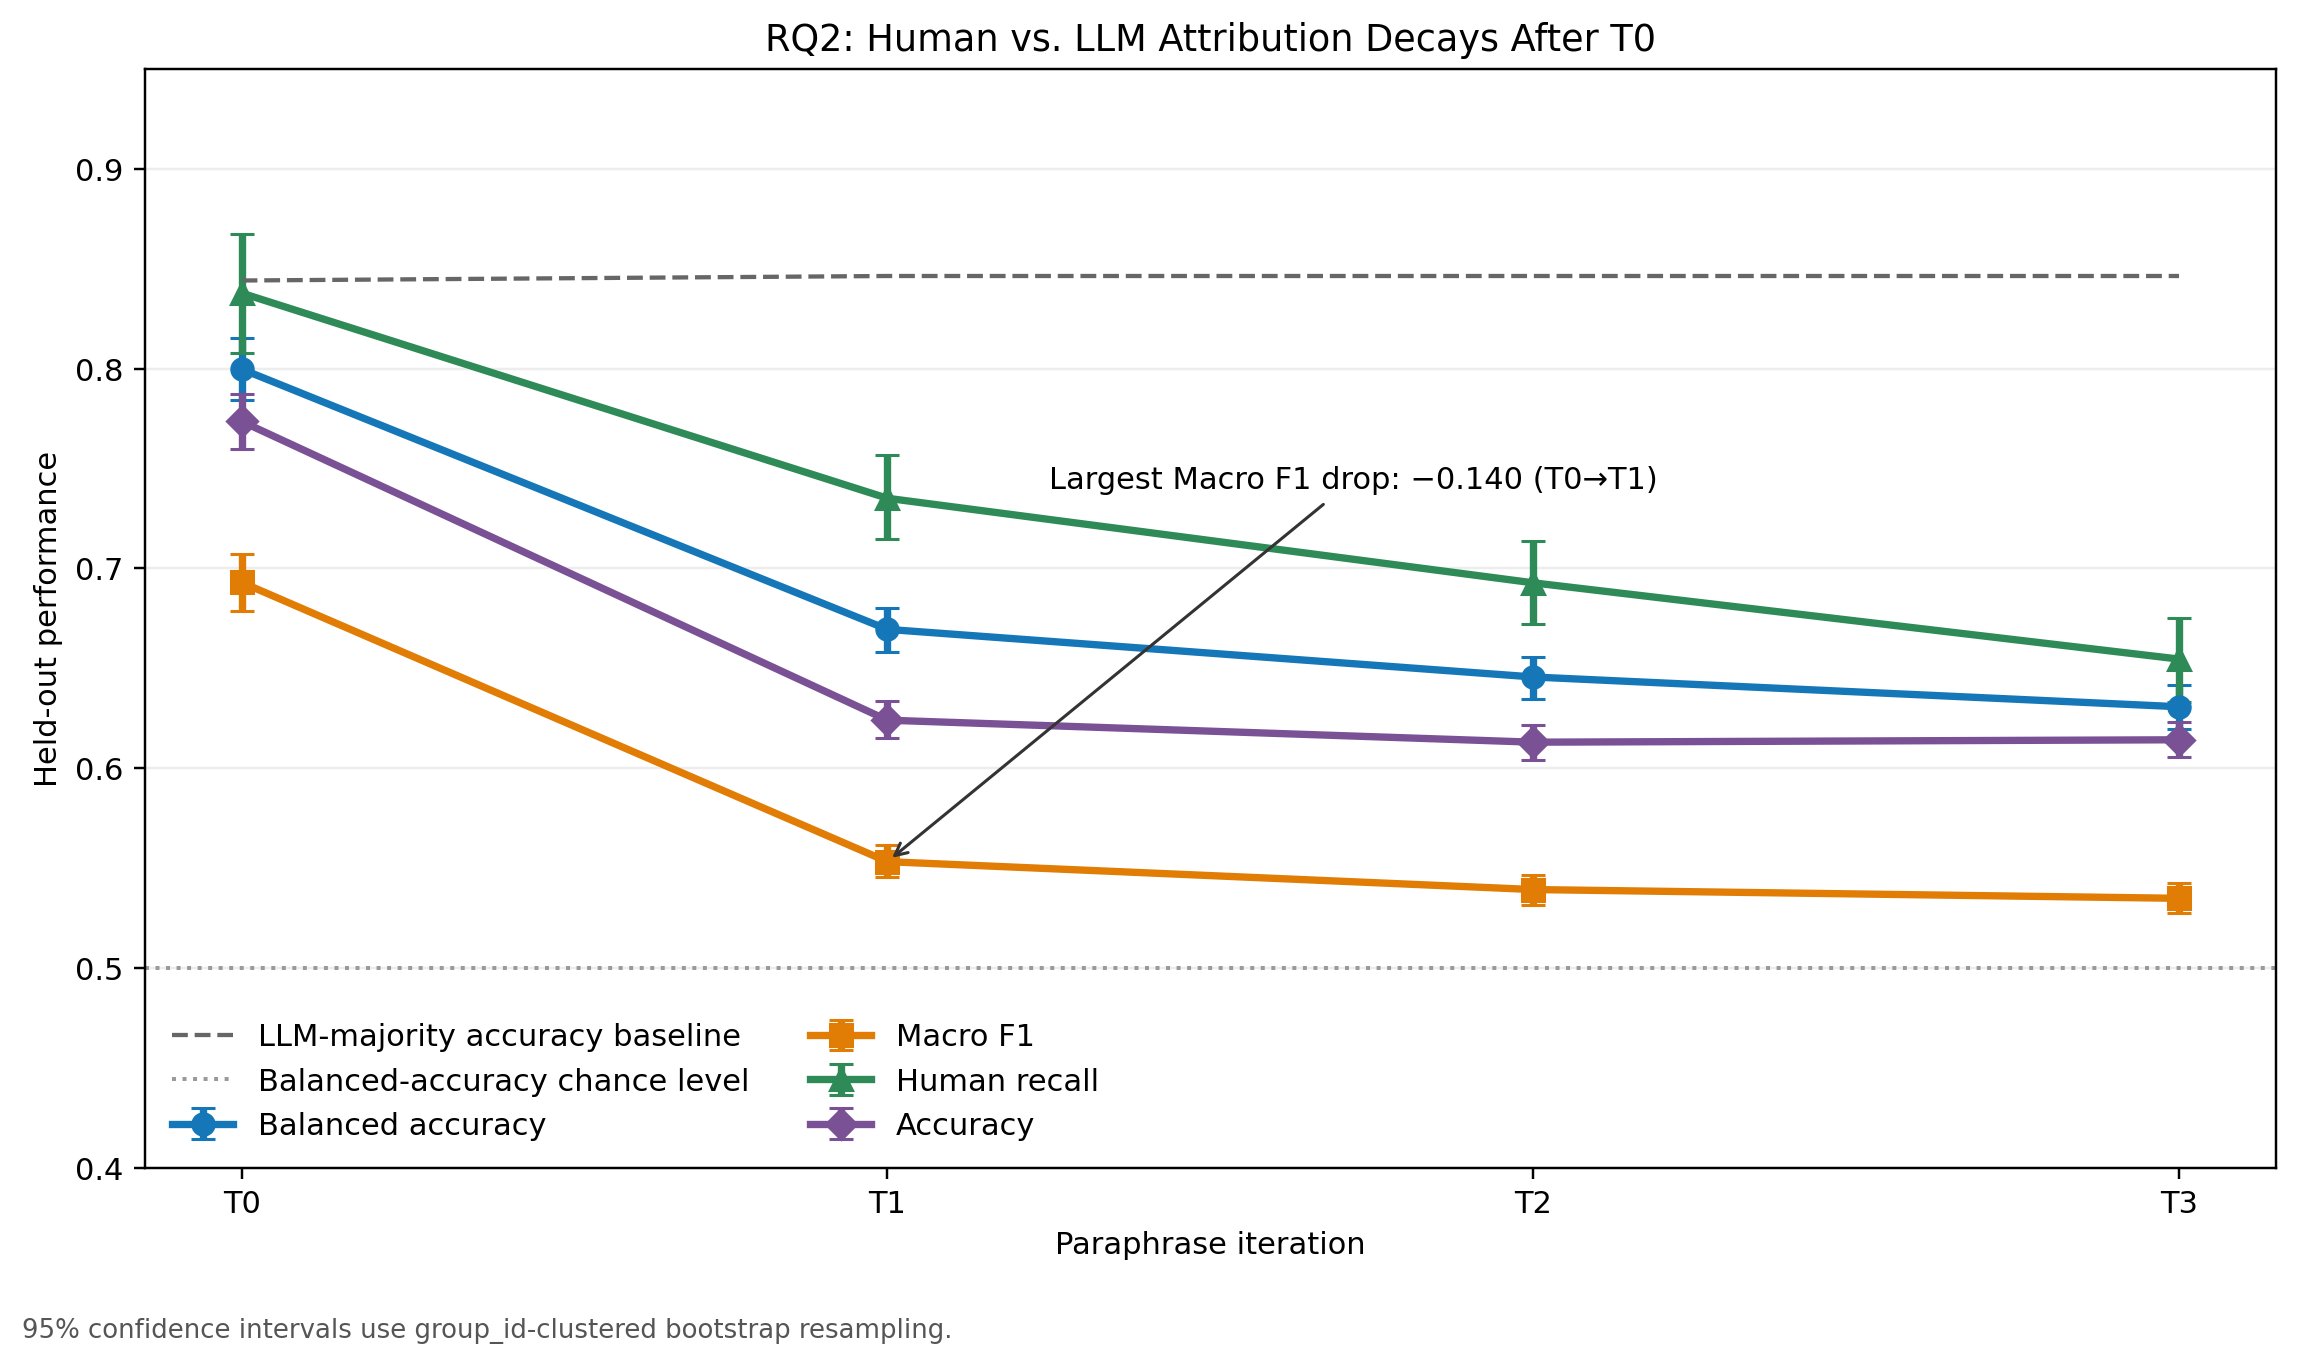

In [3]:
from IPython.display import Image, display
display(Image(filename=root / 'figures/update2/rq2_attribution_decay.png'))